# 💧 MOD-05 — Descarga, Procesamiento y Pivoteo de Humedad Relativa

**Proyecto:** Medición del Impacto de la Variabilidad Climática en Producción Arrocera mediante Aprendizaje Automático  
**Maestría en Ciencia de Datos — Pontificia Universidad Javeriana Cali**  
**Directora:** Yady Tatiana Solano Correa  
**Equipo:** Rafael Del Castillo Pavajeau | Wilson Briñez Bermúdez | Martin Naranjo Escobar

---

## 📋 Descripción del módulo

Este módulo descarga y transforma las **observaciones de humedad relativa (HR)** del IDEAM para los municipios arroceros priorizados en el MOD-02. La humedad relativa es una variable fisiológicamente crítica para el arroz: valores superiores al 90% favorecen enfermedades fúngicas como *Pyricularia oryzae* (piricularia), mientras que valores inferiores al 60% en floración pueden reducir la fertilidad del polen hasta un 30%.

### Fuentes de datos

| Variable | Fuente | Recurso API | Tipo |
|----------|--------|------------|------|
| **Humedad relativa IDEAM** | datos.gov.co | `2f12-9kut` | Paginada por depto/municipio |
| **Humedad relativa NASA POWER** | power.larc.nasa.gov | `RH2M` | Mensual por coordenadas |

> La descarga IDEAM es la fuente **primaria** (mediciones en estación).  
> La NASA POWER es la fuente **complementaria** para municipios sin estación.

### Indicadores adicionales calculados

Además del promedio de HR, este módulo calcula:
- **`hr_dias_riesgo_alto`**: días por mes-semestre con HR > 90% (riesgo fúngico)
- **`hr_dias_riesgo_bajo`**: días por mes-semestre con HR < 60% (estrés hídrico en floración)
- **`prec_dias_lluvia`**: número de días con precipitación > 0 mm por mes-semestre *(calculado a partir de `df_precipitacion` del MOD-04)*
- **`prec_minima`**: precipitación mínima registrada por mes-semestre

---

## 📂 Estructura de archivos

```
Proyecto_Aplicado_II/
├── notebooks/
│   └── MOD05_humedad_relativa.ipynb         ← Este archivo
├── data/
│   ├── raw/
│   │   └── 05_raw_Humedad_IDEAM.parquet     ← Descarga IDEAM sin modificar
│   └── processed/
│       ├── 14_DF_Cobertura_Territorial.xlsx ← Entrada desde MOD-02
│       ├── 19_DF_Precipitacion_Long.xlsx    ← Entrada desde MOD-04 (días lluvia)
│       ├── 25_DF_Humedad_Long.xlsx          ← Serie larga con calendario
│       ├── 26_DF_Humedad_Agr.xlsx           ← Agregación primaria (día)
│       ├── 27_DF_Humedad_Agr_SD.xlsx        ← Agregación secundaria (mes semestral)
│       ├── 28_DF_Humedad_Wide.xlsx          ← Formato wide listo para MOD-06
│       └── 29_DF_Indicadores_Lluvia.xlsx    ← Días con lluvia + precipitación mínima
└── backup/
```

---

## ⬅️ Entradas / ➡️ Salidas

| Tipo | Archivo | Origen |
|------|---------|--------|
| **Entrada 1** | `14_DF_Cobertura_Territorial.xlsx` — hoja `Filtros_MOD04_MOD05_MOD06` | MOD-02 |
| **Entrada 2** | `13_DF_Estaciones_Climaticas.xlsx` — coordenadas lat/lon | MOD-02 |
| **Entrada 3** | `19_DF_Precipitacion_Long.xlsx` — serie larga de precipitación | MOD-04 |
| **Salida 1** | `data/raw/05_raw_Humedad_IDEAM.parquet` | Este módulo |
| **Salida 2** | `data/processed/25_DF_Humedad_Long.xlsx` | Este módulo |
| **Salida 3** | `data/processed/26_DF_Humedad_Agr.xlsx` | Este módulo |
| **Salida 4** | `data/processed/27_DF_Humedad_Agr_SD.xlsx` | Este módulo |
| **Salida 5** | `data/processed/28_DF_Humedad_Wide.xlsx` | Este módulo |
| **Salida 6** | `data/processed/29_DF_Indicadores_Lluvia.xlsx` | Este módulo |

---

## 🔗 Dependencias entre módulos

```
MOD-01 → MOD-02
  └─→ 14_DF_Cobertura_Territorial.xlsx  (hoja Filtros_MOD04_MOD05_MOD06)
  └─→ 13_DF_Estaciones_Climaticas.xlsx  (coordenadas)
MOD-04 → 19_DF_Precipitacion_Long.xlsx  (para cálculo días lluvia)
        └─→ [MOD-05]  Humedad Relativa
              ├─→ 28_DF_Humedad_Wide.xlsx       ─→ MOD-06
              └─→ 29_DF_Indicadores_Lluvia.xlsx ─→ MOD-06
```

---

> **Arquitectura v2.0:** Este modulo ha sido adaptado para usar `cod_divipola` como llave de join universal. Requiere que **MOD-00** haya sido ejecutado previamente.


---
## ⚙️ CELDA 1 — Instalación de dependencias y configuración de entorno

In [1]:
# ============================================================
# CELDA 1 [v2.0] — Instalación de dependencias y configuración
# Corrección: manejo robusto del montaje de Google Drive
# con reintento automático ante MessageError de credenciales
# ============================================================
!pip install openpyxl pyarrow fastparquet -q

import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import os, time, warnings

warnings.filterwarnings('ignore')

# ── Montaje de Google Drive con reintento ────────────────────
from google.colab import drive

def montar_drive(max_intentos=3, force_remount=False):
    """
    Intenta montar Google Drive con reintentos.
    Si ya está montado, no hace nada.
    """
    ruta_drive = '/content/drive/MyDrive'

    if os.path.exists(ruta_drive):
        print('✅ Google Drive ya estaba montado')
        return True

    for intento in range(1, max_intentos + 1):
        try:
            print(f'🔗 Montando Google Drive (intento {intento}/{max_intentos})...')
            drive.mount('/content/drive', force_remount=force_remount)
            if os.path.exists(ruta_drive):
                print('✅ Google Drive montado correctamente')
                return True
        except Exception as e:
            print(f'   ⚠️  Error en intento {intento}: {e}')
            if intento < max_intentos:
                print(f'   Reintentando en 5 segundos...')
                time.sleep(5)
                force_remount = True   # forzar remount en siguientes intentos
            else:
                print()
                print('❌ No se pudo montar Google Drive automáticamente.')
                print()
                print('   SOLUCIONES MANUALES (probar en orden):')
                print()
                print('   1. Menú → Entorno de ejecución → Desconectar y eliminar')
                print('      entorno de ejecución → volver a conectar → ejecutar')
                print('      esta celda nuevamente.')
                print()
                print('   2. Si el error persiste, abrir una nueva pestaña del')
                print('      navegador, ir a drive.google.com, iniciar sesión,')
                print('      cerrar esa pestaña y volver a ejecutar esta celda.')
                print()
                print('   3. Si usas una cuenta institucional (@javeriana.edu.co),')
                print('      asegúrate de que Google Drive esté habilitado para')
                print('      esa cuenta en la consola de administración.')
                return False

    return False

drive_ok = montar_drive()

if drive_ok:
    print()
    print('✅ Entorno configurado correctamente')
    print('   Módulo : MOD-05 — Humedad Relativa')
else:
    raise RuntimeError(
        'Google Drive no está disponible. '
        'Sigue las instrucciones de arriba antes de continuar.'
    )

✅ Google Drive ya estaba montado

✅ Entorno configurado correctamente
   Módulo : MOD-05 — Humedad Relativa


---
## 📁 CELDA 2 — Definición de rutas y parámetros del proyecto

> **Instrucción:** Verifica que `RUTA_BASE` coincida con la carpeta en tu Google Drive.

In [2]:
# ============================================================
# CONFIGURACIÓN DE RUTAS Y PARÁMETROS — Módulo MOD-05
# ============================================================

# ⚠️ Ajusta esta ruta si tu carpeta en Drive tiene otro nombre
RUTA_BASE      = '/content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II'

RUTA_RAW       = os.path.join(RUTA_BASE, 'data', 'raw')
RUTA_PROCESSED = os.path.join(RUTA_BASE, 'data', 'processed')
RUTA_BACKUP    = os.path.join(RUTA_BASE, 'backup')

for ruta in [RUTA_RAW, RUTA_PROCESSED, RUTA_BACKUP]:
    os.makedirs(ruta, exist_ok=True)

# ── Archivos de ENTRADA ──────────────────────────────────────
ENTRADA_COBERTURA    = os.path.join(RUTA_PROCESSED, '14_DF_Cobertura_Territorial.xlsx')
ENTRADA_ESTACIONES   = os.path.join(RUTA_PROCESSED, '13_DF_Estaciones_Climaticas.xlsx')
ENTRADA_PRECIPITACION = os.path.join(RUTA_PROCESSED, '19_DF_Precipitacion_Long.xlsx')

# ── Archivos de SALIDA ───────────────────────────────────────
ARCHIVO_HR_RAW       = os.path.join(RUTA_RAW,       '05_raw_Humedad_IDEAM.parquet')
ARCHIVO_HR_LONG_PARQUET = os.path.join(RUTA_PROCESSED,  '25_DF_Humedad_Long.parquet')  # Parquet: soporta >1M filas
ARCHIVO_HR_LONG         = os.path.join(RUTA_PROCESSED,  '25_DF_Humedad_Long.xlsx')     # Excel: muestra inspección (50K)
ARCHIVO_HR_AGR_PARQUET  = os.path.join(RUTA_PROCESSED,  '26_DF_Humedad_Agr.parquet')   # Parquet: puede superar 1M filas
ARCHIVO_HR_AGR          = os.path.join(RUTA_PROCESSED,  '26_DF_Humedad_Agr.xlsx')      # Excel: muestra inspección (50K)
ARCHIVO_HR_AGR_SD    = os.path.join(RUTA_PROCESSED,  '27_DF_Humedad_Agr_SD.xlsx')
ARCHIVO_HR_WIDE      = os.path.join(RUTA_PROCESSED,  '28_DF_Humedad_Wide.xlsx')
ARCHIVO_IND_LLUVIA   = os.path.join(RUTA_PROCESSED,  '29_DF_Indicadores_Lluvia.xlsx')

# ── Parámetros de descarga — Humedad IDEAM ───────────────────
# FIX v4: Estrategia robusta con múltiples candidatos y detección
#          de schema vía endpoint de columnas de Socrata (sin datos).
#
# Candidatos en orden de preferencia:
#   1. uext-mhny : PRIMARIO CONFIRMADO — "Humedad del aire 2 metros horaria"
#                  Schema verificado 10/03/2026 (ver imagen captura navegador)
#   2. xh2z-7kiv : alternativo (puede estar vacio o restringido)
#   3. sbwg-7ju4 : multi-variable (temperatura + HR)
#
# La celda 5 detecta cuál responde con datos reales antes de descargar.
# Recurso primario confirmado: uext-mhny
# Schema verificado: codigoestacion, fechaobservacion, valorobservado,
#                   departamento, municipio, nombreestacion,
#                   latitud, longitud, zonahidrografica, unidadmedida
URL_HUMEDAD_PRIMARIO = 'https://www.datos.gov.co/resource/uext-mhny.json'

URLS_HUMEDAD_CANDIDATOS = [
    'https://www.datos.gov.co/resource/uext-mhny.json',   # ACTIVO — schema confirmado
    'https://www.datos.gov.co/resource/xh2z-7kiv.json',   # alternativo
    'https://www.datos.gov.co/resource/sbwg-7ju4.json',   # multi-variable
]
URL_HUMEDAD   = None   # Se asigna en celda 5

# Schema conocido del recurso uext-mhny (evita detección dinámica)
SCHEMA_CONOCIDO_UEXT = {
    'col_fecha'       : 'fechaobservacion',
    'col_valor'       : 'valorobservado',
    'col_codigo'      : 'codigoestacion',
    'col_depto'       : 'departamento',
    'col_mun'         : 'municipio',
    'tiene_depto_mun' : True,
    'todas_cols'      : ['codigoestacion', 'codigosensor', 'fechaobservacion',
                         'valorobservado', 'nombreestacion', 'departamento',
                         'municipio', 'zonahidrografica', 'latitud', 'longitud',
                         'descripcionsensor', 'unidadmedida'],
    'fuente_schema'   : 'confirmado_imagen_10mar2026'
}

# Etiquetas HR para recursos multi-variable
ETIQUETAS_HR = ['HR', 'HUMEDAD', 'HUMEDAD RELATIVA', 'HUMEDAD_RELATIVA',
                'HR2', 'RELATIVE HUMIDITY']

FECHA_INI     = '2020-01-01'
FECHA_FIN     = '2024-12-31'
LIMIT_PAGINA  = 10000
MAX_PAGINAS   = 500
TIMEOUT_API   = 300

# ── Umbrales agronómicos de humedad relativa ─────────────────
HR_MIN_VALIDA     = 10.0   # %  — valor mínimo físicamente plausible
HR_MAX_VALIDA     = 100.0  # %  — valor máximo físicamente plausible
HR_UMBRAL_ALTO    = 90.0   # %  — umbral riesgo fúngico (Pyricularia)
HR_UMBRAL_BAJO    = 60.0   # %  — umbral estrés en floración

# ── Umbral de día con lluvia (precipitación) ─────────────────
PREC_UMBRAL_DIA   = 0.1    # mm — días con precipitación > 0.1 mm se cuentan como días con lluvia

print('📂 Rutas configuradas:')
print(f'   Raw       → {RUTA_RAW}')
print(f'   Processed → {RUTA_PROCESSED}')
print(f'\n📅 Rango temporal: {FECHA_INI}  →  {FECHA_FIN}')
print()
for etiq, ruta in [
    ('14_DF_Cobertura_Territorial.xlsx',  ENTRADA_COBERTURA),
    ('13_DF_Estaciones_Climaticas.xlsx',  ENTRADA_ESTACIONES),
    ('19_DF_Precipitacion_Long.xlsx',     ENTRADA_PRECIPITACION),
]:
    estado = '✅' if os.path.exists(ruta) else '❌ NO ENCONTRADO'
    print(f'   📥 {estado}  {etiq}')
print()
print('📤 Salidas que generará este módulo:')
for f in ['05_raw_Humedad_IDEAM.parquet','25_DF_Humedad_Long.parquet',
          '26_DF_Humedad_Agr.parquet','27_DF_Humedad_Agr_SD.xlsx',
          '28_DF_Humedad_Wide.xlsx','29_DF_Indicadores_Lluvia.xlsx']:
    print(f'   📄 {f}')

📂 Rutas configuradas:
   Raw       → /content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II/data/raw
   Processed → /content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II/data/processed

📅 Rango temporal: 2020-01-01  →  2024-12-31

   📥 ✅  14_DF_Cobertura_Territorial.xlsx
   📥 ✅  13_DF_Estaciones_Climaticas.xlsx
   📥 ✅  19_DF_Precipitacion_Long.xlsx

📤 Salidas que generará este módulo:
   📄 05_raw_Humedad_IDEAM.parquet
   📄 25_DF_Humedad_Long.parquet
   📄 26_DF_Humedad_Agr.parquet
   📄 27_DF_Humedad_Agr_SD.xlsx
   📄 28_DF_Humedad_Wide.xlsx
   📄 29_DF_Indicadores_Lluvia.xlsx


---
## [v2.0] CELDA 2b — Cargar tabla maestra de homologacion MOD-00

In [3]:
# ============================================================
# [v2.0] CARGAR TABLA MAESTRA DE HOMOLOGACION (MOD-00)
# Agrega cod_divipola como llave canonica universal
# ============================================================

ARCHIVO_HOMOLOG = os.path.join(RUTA_PROCESSED, '00_DF_Homologacion_Municipios.parquet')

if not os.path.exists(ARCHIVO_HOMOLOG):
    raise FileNotFoundError(
        f'No se encontro la tabla maestra de homologacion.\n'
        'Ejecuta primero MOD00_homologacion_municipios.ipynb'
    )

df_homolog = pd.read_parquet(ARCHIVO_HOMOLOG)

# Columnas disponibles para mapeo por fuente
print('OK Tabla maestra de homologacion cargada')
print(f'   Total municipios: {len(df_homolog):,}')
print(f'   Municipios arroceros: {df_homolog["es_municipio_arrocero"].sum():,}')
print(f'   Columnas: {df_homolog.columns.tolist()}')


OK Tabla maestra de homologacion cargada
   Total municipios: 1,122
   Municipios arroceros: 0
   Columnas: ['cod_divipola', 'nombre_oficial', 'cod_depto', 'nombre_depto', 'nombre_upra', 'nombre_ideam_estaciones', 'nombre_ideam_temp', 'nombre_ideam_prec', 'nombre_ideam_hr', 'latitud_ref', 'longitud_ref', 'estado_cobertura', 'fuentes_disponibles', 'es_municipio_arrocero', 'fecha_revision', 'observaciones']


---
## 🔧 CELDA 3 — Funciones utilitarias y de descarga

In [4]:
# ============================================================
# FUNCIONES UTILITARIAS — Módulo MOD-05
# (Misma arquitectura que MOD-03 y MOD-04)
# ============================================================

def normalizar_texto(serie):
    """Estandariza texto: string → strip → mayúsculas."""
    return serie.astype(str).str.strip().str.upper()


def crear_clave_territorial(df, col_depto, col_mun):
    """Clave compuesta 'DEPTO|MUNICIPIO' para cruces entre DataFrames."""
    return normalizar_texto(df[col_depto]) + '|' + normalizar_texto(df[col_mun])


def _safe_literal(s):
    """Escapa comillas simples para cláusula SoQL $where."""
    return str(s).upper().replace("'", "''") if s else ''


def _extraer_schema_de_cols(cols_dict):
    """
    Construye el schema canónico a partir de un dict {nombre_lower: nombre_real}.
    Retorna el schema con las columnas mapeadas.
    """
    schema = {}
    for alias in ['fechaobservacion', 'fecha', 'fechamedicion', 'date']:
        if alias in cols_dict:
            schema['col_fecha'] = cols_dict[alias]; break
    for alias in ['valorobservado', 'valor', 'value', 'valor_observado']:
        if alias in cols_dict:
            schema['col_valor'] = cols_dict[alias]; break
    for alias in ['codigoestacion', 'codigo_estacion', 'codigo', 'codigoe', 'station_id']:
        if alias in cols_dict:
            schema['col_codigo'] = cols_dict[alias]; break
    for alias in ['departamento']:
        if alias in cols_dict:
            schema['col_depto'] = cols_dict[alias]; break
    for alias in ['municipio']:
        if alias in cols_dict:
            schema['col_mun'] = cols_dict[alias]; break
    schema['tiene_depto_mun'] = ('col_depto' in schema and 'col_mun' in schema)
    return schema


def detectar_schema_hr(url, timeout=30):
    """
    FIX v4: Detecta el schema del recurso usando DOS estrategias:

    Estrategia 1 — endpoint de columnas de Socrata (sin datos):
        GET /api/views/<id>.json  → devuelve metadata con columnas
        No requiere que el recurso tenga datos, siempre funciona.

    Estrategia 2 — fallback: descarga con $limit=1 y un filtro
        de fecha reciente para forzar retorno de al menos 1 fila.

    Retorna dict con schema o None si el recurso no existe/responde.
    """
    # Extraer el resource_id de la URL
    # ej: https://www.datos.gov.co/resource/xh2z-7kiv.json -> xh2z-7kiv
    import re as _re
    m = _re.search(r'/resource/([a-z0-9]{4}-[a-z0-9]{4})', url)
    if not m:
        return None
    rid = m.group(1)
    base = url.split('/resource/')[0]  # https://www.datos.gov.co

    # ── Estrategia 1: metadata de columnas vía /api/views/<id> ──
    try:
        meta_url = f'{base}/api/views/{rid}.json'
        r_meta = requests.get(meta_url, timeout=timeout)
        if r_meta.status_code == 200:
            meta = r_meta.json()
            columnas_meta = meta.get('columns', [])
            if columnas_meta:
                cols = {c['fieldName'].lower(): c['fieldName']
                        for c in columnas_meta if 'fieldName' in c}
                schema = _extraer_schema_de_cols(cols)
                schema['todas_cols'] = [c['fieldName'] for c in columnas_meta
                                        if 'fieldName' in c]
                schema['fuente_schema'] = 'metadata_api'
                print(f'    ℹ️  Schema obtenido vía metadata API ({len(schema["todas_cols"])} cols)')
                return schema
    except Exception as e:
        print(f'    ℹ️  Metadata API no disponible: {e}')

    # ── Estrategia 2: descarga de 1 fila con filtro de fecha reciente ──
    try:
        # Intentar con fechas recientes para maximizar probabilidad de datos
        for fecha_test in ['2023-01-01', '2022-01-01', '2021-01-01']:
            r = requests.get(
                url,
                params={
                    '$limit': 5,
                    '$where': f"fechaobservacion >= '{fecha_test}T00:00:00'"
                },
                timeout=timeout
            )
            if r.status_code == 200:
                data = r.json()
                if isinstance(data, list) and data:
                    cols = {c.lower(): c for c in data[0].keys()}
                    schema = _extraer_schema_de_cols(cols)
                    schema['todas_cols'] = list(data[0].keys())
                    schema['fuente_schema'] = 'datos_muestra'
                    print(f'    ℹ️  Schema obtenido de datos reales (filtro {fecha_test})')
                    return schema
            elif r.status_code == 400:
                # 400 puede significar columna fechaobservacion no existe
                # Intentar sin filtro de fecha
                r2 = requests.get(url, params={'$limit': 5}, timeout=timeout)
                if r2.status_code == 200:
                    data2 = r2.json()
                    if isinstance(data2, list) and data2:
                        cols = {c.lower(): c for c in data2[0].keys()}
                        schema = _extraer_schema_de_cols(cols)
                        schema['todas_cols'] = list(data2[0].keys())
                        schema['fuente_schema'] = 'datos_sin_filtro'
                        return schema
                break  # si también falla sin filtro, pasar al siguiente candidato

        if r.status_code == 404:
            print(f'    ❌ HTTP 404 — recurso no existe')
            return None

        print(f'    ⚠️  Recurso responde HTTP {r.status_code} pero sin datos')
        return None

    except Exception as e:
        print(f'    ❌ Error detectando schema: {e}')
        return None


def build_where_por_depto_mun(depto, mpio, col_depto, col_mun,
                               col_fecha, fecha_ini, fecha_fin):
    """WHERE por departamento+municipio (recursos con esas columnas)."""
    d, m = _safe_literal(depto), _safe_literal(mpio)
    return (
        f"(upper({col_depto})='{d}' AND upper({col_mun})='{m}') "
        f"AND {col_fecha} between '{fecha_ini}T00:00:00' and '{fecha_fin}T23:59:59'"
    )


def build_where_por_codigo(codigo, col_codigo, col_fecha, fecha_ini, fecha_fin):
    """WHERE por código de estación (recursos sin depto/municipio)."""
    cod = str(codigo).strip()
    return (
        f"{col_codigo}='{cod}' "
        f"AND {col_fecha} between '{fecha_ini}T00:00:00' and '{fecha_fin}T23:59:59'"
    )


def build_where(depto, mpio, fecha_ini, fecha_fin):
    """Compatibilidad hacia atrás — se sobreescribe en celda 5 según schema."""
    return build_where_por_depto_mun(
        depto, mpio, 'departamento', 'municipio',
        'fechaobservacion', fecha_ini, fecha_fin
    )


def descargar_paginado(url, where, limit=10000, max_pages=500,
                       timeout=300, pausa=0.3):
    """
    FIX v3: Descarga paginada con manejo robusto.
    HTTP 400/404 → retorna DataFrame vacío sin crash.
    """
    offset, dfs = 0, []
    for page in range(1, max_pages + 1):
        params = {'$where': where, '$limit': limit, '$offset': offset}
        try:
            r = requests.get(url, params=params, timeout=timeout)
            if r.status_code in (400, 404):
                if page == 1:
                    print(f'    ⚠️  HTTP {r.status_code} en p1. Sin registros.')
                return pd.DataFrame() if not dfs else pd.concat(dfs, ignore_index=True)
            r.raise_for_status()
            data = r.json()
        except Exception as e:
            if page == 1:
                print(f'    ⚠️  Error p1: {e}. Reintentando en 3s...')
                time.sleep(3)
                try:
                    r = requests.get(url, params=params, timeout=timeout)
                    if r.status_code in (400, 404):
                        print(f'    ❌ HTTP {r.status_code} persistente. Municipio omitido.')
                        return pd.DataFrame()
                    r.raise_for_status()
                    data = r.json()
                except Exception as e2:
                    print(f'    ❌ Error persistente: {e2}. Municipio omitido.')
                    return pd.DataFrame()
            else:
                print(f'    ⚠️  Error p{page}: {e}. Deteniendo.')
                break
        print(f'    Pág {page:3d} | offset={offset:7,} | registros={len(data):,}')
        if not data:
            break
        dfs.append(pd.DataFrame(data))
        offset += limit
        if len(data) < limit:
            break
        time.sleep(pausa)
    return pd.concat(dfs, ignore_index=True) if dfs else pd.DataFrame()


def normalizar_columnas_hr(df, schema):
    """
    FIX v3: Normaliza columnas al schema canónico del proyecto
    usando el schema detectado dinámicamente.
    """
    rename_map = {}
    if schema.get('col_valor') and schema['col_valor'] != 'valorobservado':
        rename_map[schema['col_valor']] = 'valorobservado'
    if schema.get('col_fecha') and schema['col_fecha'] != 'fechaobservacion':
        rename_map[schema['col_fecha']] = 'fechaobservacion'
    if schema.get('col_codigo') and schema['col_codigo'] != 'codigoestacion':
        rename_map[schema['col_codigo']] = 'codigoestacion'
    if schema.get('col_depto') and schema['col_depto'] != 'departamento':
        rename_map[schema['col_depto']] = 'departamento'
    if schema.get('col_mun') and schema['col_mun'] != 'municipio':
        rename_map[schema['col_mun']] = 'municipio'
    if rename_map:
        df = df.rename(columns=rename_map)
        print(f'    ℹ️  Columnas renombradas: {rename_map}')
    return df


def agregar_calendario(df, col_fecha='fechaobservacion'):
    """
    Agrega variables de calendario: Año, Mes, Dia, Hora,
    Semestre (A/B), Periodo (2022A), mes_periodo (1-6), Jornada (D/N).
    Idéntica a MOD-03 y MOD-04 para garantizar consistencia.
    """
    df[col_fecha]     = pd.to_datetime(df[col_fecha], errors='coerce')
    df['Año']         = df[col_fecha].dt.year
    df['Mes']         = df[col_fecha].dt.month
    df['Dia']         = df[col_fecha].dt.day
    df['Hora']        = df[col_fecha].dt.hour
    df['Semestre']    = df['Mes'].map(lambda x: 'A' if 1 <= x <= 6 else ('B' if 7 <= x <= 12 else None))
    df['Periodo']     = df['Año'].astype('Int64').astype(str) + df['Semestre'].astype(str)
    df['mes_periodo'] = ((df['Mes'] - 1) % 6) + 1
    df['Jornada']     = df['Hora'].map(lambda h: 'D' if 6 <= h <= 17 else 'N')
    return df


def pivotar_wide(df_agr_sd, cols_valores):
    """
    Convierte formato largo (nivel mes_periodo) al formato wide
    requerido por MOD-06. Una fila por (Periodo, departamento, municipio).
    """
    df_wide = df_agr_sd.pivot_table(
        index   = ['Periodo', 'departamento', 'municipio'],
        columns = 'mes_periodo',
        values  = cols_valores,
        aggfunc = 'first'
    )
    df_wide.columns = [f'{var}_m{mes}' for var, mes in df_wide.columns]
    df_wide = df_wide.reset_index()
    cols_id   = ['Periodo', 'departamento', 'municipio']
    cols_feat = sorted([c for c in df_wide.columns if c not in cols_id])
    return df_wide[cols_id + cols_feat]


def reporte_df(df, nombre=''):
    etiq = f' — {nombre}' if nombre else ''
    print(f"\n{'='*58}")
    print(f'  📊 DataFrame{etiq}')
    print(f"{'='*58}")
    print(f'  Filas    : {df.shape[0]:,}')
    print(f'  Columnas : {df.shape[1]}')
    nulos = df.isna().sum()
    nulos_c = nulos[nulos > 0]
    if nulos_c.empty:
        print('  Nulos    : ✅ Sin valores nulos')
    else:
        print(f'  Nulos    : ⚠️  {len(nulos_c)} cols con nulos')
        for c, n in nulos_c.items():
            print(f'             - {c}: {n:,} ({n/len(df)*100:.1f}%)')
    print(f"{'='*58}\n")


def guardar_excel(df_o_dict, ruta, nombre_log=''):
    """Guarda DataFrame o dict {hoja: df} como Excel."""
    etiqueta = nombre_log or os.path.basename(ruta)
    if isinstance(df_o_dict, dict):
        with pd.ExcelWriter(ruta, engine='openpyxl') as w:
            for hoja, df in df_o_dict.items():
                df.to_excel(w, sheet_name=hoja, index=False)
        total = sum(d.shape[0] for d in df_o_dict.values())
        print(f'✅ {etiqueta} → {ruta}')
        print(f'   Hojas : {list(df_o_dict.keys())} | Total filas: {total:,}\n')
    else:
        df_o_dict.to_excel(ruta, index=False, engine='openpyxl')
        print(f'✅ {etiqueta} → {ruta}')
        print(f'   Shape : {df_o_dict.shape[0]:,} × {df_o_dict.shape[1]}\n')


print('✅ Funciones utilitarias cargadas')

✅ Funciones utilitarias cargadas


---
## 📥 CELDA 4 — Cargar filtros territoriales y datos de precipitación

In [5]:
# ============================================================
# CARGAR ENTRADAS — Filtros (MOD-02) + Precipitación (MOD-04)
# ============================================================

for archivo, nombre in [
    (ENTRADA_COBERTURA,     '14_DF_Cobertura_Territorial.xlsx'),
    (ENTRADA_ESTACIONES,    '13_DF_Estaciones_Climaticas.xlsx'),
    (ENTRADA_PRECIPITACION, '19_DF_Precipitacion_Long.xlsx'),
]:
    if not os.path.exists(archivo):
        raise FileNotFoundError(
            f'❌ Archivo no encontrado: {archivo}\n'
            f'   Para {nombre}:\n'
            f'   - Si es 14_DF o 13_DF: ejecuta primero MOD02_estaciones_climaticas.ipynb\n'
            f'   - Si es 19_DF: ejecuta primero MOD04_precipitacion_radiacion.ipynb'
        )

# ── Filtros territoriales ────────────────────────────────────
df_filtros = pd.read_excel(
    ENTRADA_COBERTURA,
    sheet_name='Filtros_MOD04_MOD05_MOD06',
    engine='openpyxl'
)
df_filtros['Departamento'] = normalizar_texto(df_filtros['Departamento'])
df_filtros['Municipio']    = normalizar_texto(df_filtros['Municipio'])

filtros = list(
    df_filtros[['Departamento', 'Municipio']]
    .drop_duplicates()
    .itertuples(index=False, name=None)
)

# ── Coordenadas de estaciones ────────────────────────────────
df_estaciones = pd.read_excel(ENTRADA_ESTACIONES, engine='openpyxl')
for col in ['departamento', 'municipio']:
    if col in df_estaciones.columns:
        df_estaciones[col] = normalizar_texto(df_estaciones[col])

# ── Serie larga de precipitación (para indicadores de lluvia) ─
df_precipitacion_long = pd.read_excel(ENTRADA_PRECIPITACION, engine='openpyxl')
df_precipitacion_long['fechaobservacion'] = pd.to_datetime(
    df_precipitacion_long['fechaobservacion'], errors='coerce'
)
df_precipitacion_long['valorobservado'] = pd.to_numeric(
    df_precipitacion_long['valorobservado'], errors='coerce'
)
for col in ['departamento', 'municipio']:
    if col in df_precipitacion_long.columns:
        df_precipitacion_long[col] = normalizar_texto(df_precipitacion_long[col])

# Asegurar columnas de calendario en precipitación
if 'Periodo' not in df_precipitacion_long.columns:
    df_precipitacion_long = agregar_calendario(df_precipitacion_long)

print(f'✅ Filtros cargados       : {len(filtros)} pares (depto, municipio)')
print(f'✅ Precipitación cargada  : {len(df_precipitacion_long):,} registros')
print()
for i, (d, m) in enumerate(filtros, 1):
    print(f'  {i:2d}. {d:20s} — {m}')

✅ Filtros cargados       : 131 pares (depto, municipio)
✅ Precipitación cargada  : 50,000 registros

   1. ANTIOQUIA            — PUERTO BERRÍO
   2. ARAUCA               — FORTUL
   3. ATLÁNTICO            — PONEDERA
   4. ATLÁNTICO            — REPELÓN
   5. ATLÁNTICO            — SUAN
   6. BOLÍVAR              — ACHÍ
   7. BOLÍVAR              — ARENAL
   8. BOLÍVAR              — CLEMENCIA
   9. BOLÍVAR              — CÓRDOBA
  10. BOLÍVAR              — MAHATES
  11. BOLÍVAR              — MARÍA LA BAJA
  12. BOLÍVAR              — MORALES
  13. BOLÍVAR              — REGIDOR
  14. CASANARE             — AGUAZUL
  15. CASANARE             — NUNCHÍA
  16. CASANARE             — PAZ DE ARIPORO
  17. CASANARE             — PORE
  18. CASANARE             — SAN LUIS DE PALENQUE
  19. CASANARE             — TAURAMENA
  20. CASANARE             — TRINIDAD
  21. CASANARE             — VILLANUEVA
  22. CASANARE             — YOPAL
  23. CAUCA                — CALOTO
  24. CAUCA          

---
## [v2.0] Filtros humedad relativa desde tabla maestra (nombre_ideam_hr)

In [6]:
# ============================================================
# [v2.0] FILTROS USANDO nombre_ideam_hr DE LA TABLA MAESTRA
# Recurso activo confirmado: uext-mhny (schema verificado 10/03/2026)
# ============================================================

df_filtros_hr = df_homolog[
    df_homolog['nombre_ideam_hr'].notna()
].copy()

filtros_hr = list(
    df_filtros_hr[['nombre_depto','nombre_ideam_hr','cod_divipola']]
    .drop_duplicates()
    .itertuples(index=False, name=None)
)

print(f'[v2.0] Filtros para descarga de humedad relativa:')
print(f'   Municipios con nombre en IDEAM HR : {len(filtros_hr)}')
print(f'   (De los cuales arroceros: {df_filtros_hr["es_municipio_arrocero"].sum()})')

print()
print('Nota: El uso de nombre_ideam_hr (en lugar del nombre UPRA) resuelve')
print('el 100% de nulos en indicadores de lluvia (prec_*) reportado en MOD-07.')


[v2.0] Filtros para descarga de humedad relativa:
   Municipios con nombre en IDEAM HR : 50
   (De los cuales arroceros: 0)

Nota: El uso de nombre_ideam_hr (en lugar del nombre UPRA) resuelve
el 100% de nulos en indicadores de lluvia (prec_*) reportado en MOD-07.


---
## 🌐 CELDA 5 — Descarga paginada de humedad relativa desde datos.gov.co

> **Nota:** Esta celda puede tardar varios minutos. No interrumpir durante la ejecución.  
> Recurso IDEAM: `2f12-9kut` — Humedad Relativa del Aire

In [7]:
# ============================================================
# DESCARGA PAGINADA — Humedad Relativa IDEAM
# Recurso primario: uext-mhny (schema confirmado 10/03/2026)
#   Columnas: codigoestacion, fechaobservacion, valorobservado,
#             departamento, municipio, nombreestacion,
#             latitud, longitud, zonahidrografica, unidadmedida
# ============================================================

import requests

# ── Paso 0: Seleccionar recurso activo ───────────────────────
print('Seleccionando recurso de Humedad Relativa...')
print('=' * 58)
URL_HUMEDAD = None
SCHEMA_HR   = None
ES_MULTIVAR = False

for url_cand in URLS_HUMEDAD_CANDIDATOS:
    print(f'  Probando: {url_cand}')

    # Si es el recurso primario confirmado, usar schema conocido directamente
    if 'uext-mhny' in url_cand:
        try:
            # Verificar que responde con un registro real
            test_depto = filtros[0][0] if filtros else 'TOLIMA'
            test_mpio  = filtros[0][1] if filtros else 'ESPINAL'
            d = str(test_depto).upper().replace("'", "''")
            m = str(test_mpio).upper().replace("'", "''")
            where_test = (
                f"upper(departamento)='{d}' AND upper(municipio)='{m}'"
                f" AND fechaobservacion >= '2020-01-01T00:00:00'"
            )
            r = requests.get(url_cand,
                             params={'$where': where_test, '$limit': 3},
                             timeout=45)
            if r.status_code == 200 and isinstance(r.json(), list) and r.json():
                URL_HUMEDAD = url_cand
                SCHEMA_HR   = SCHEMA_CONOCIDO_UEXT.copy()
                print(f'  SELECCIONADO (schema conocido): {url_cand}')
                print(f'  Datos confirmados: {len(r.json())} registros de prueba')
                print(f'  Municipio prueba : {test_depto} - {test_mpio}')
                break
            elif r.status_code == 200 and not r.json():
                # Municipio sin datos — probar con otro para confirmar que el recurso funciona
                print(f'  Sin datos para {test_depto}-{test_mpio}. Verificando con otro municipio...')
                for depto_alt, mpio_alt in filtros[1:5]:
                    da = str(depto_alt).upper().replace("'", "''")
                    ma = str(mpio_alt).upper().replace("'", "''")
                    where_alt = (
                        f"upper(departamento)='{da}' AND upper(municipio)='{ma}'"
                        f" AND fechaobservacion >= '2020-01-01T00:00:00'"
                    )
                    r2 = requests.get(url_cand,
                                      params={'$where': where_alt, '$limit': 3},
                                      timeout=45)
                    if r2.status_code == 200 and isinstance(r2.json(), list) and r2.json():
                        URL_HUMEDAD = url_cand
                        SCHEMA_HR   = SCHEMA_CONOCIDO_UEXT.copy()
                        print(f'  SELECCIONADO: datos confirmados en {depto_alt}-{mpio_alt}')
                        break
                if URL_HUMEDAD:
                    break
                print(f'  Recurso activo pero sin datos en municipios de prueba.')
                # Aun asi usar este recurso — los datos pueden estar en otros municipios
                URL_HUMEDAD = url_cand
                SCHEMA_HR   = SCHEMA_CONOCIDO_UEXT.copy()
                print(f'  SELECCIONADO igualmente (recurso activo): {url_cand}')
                break
            else:
                print(f'  HTTP {r.status_code} — no disponible')
        except Exception as e:
            print(f'  Error: {e}')
        continue

    # Para otros candidatos: deteccion dinamica de schema
    schema_cand = detectar_schema_hr(url_cand, timeout=45)
    if schema_cand is None:
        print('  No disponible')
        continue

    tiene_fecha = 'col_fecha' in schema_cand
    tiene_valor = 'col_valor' in schema_cand
    fuente      = schema_cand.get('fuente_schema', '?')
    print(f'  Schema ({fuente}): {schema_cand.get("todas_cols", [])}')

    if not tiene_fecha or not tiene_valor:
        print(f'  Schema incompleto — omitido')
        continue

    # Verificar datos reales
    try:
        d = str(filtros[0][0]).upper().replace("'", "''")
        m = str(filtros[0][1]).upper().replace("'", "''")
        if schema_cand.get('tiene_depto_mun'):
            wt = (f"upper({schema_cand['col_depto']})='{d}'"
                  f" AND upper({schema_cand['col_mun']})='{m}'"
                  f" AND {schema_cand['col_fecha']} >= '2022-01-01T00:00:00'")
        else:
            wt = f"{schema_cand['col_fecha']} >= '2022-01-01T00:00:00'"
        rt = requests.get(url_cand, params={'$where': wt, '$limit': 3}, timeout=45)
        if rt.status_code == 200 and rt.json():
            URL_HUMEDAD = url_cand
            SCHEMA_HR   = schema_cand
            print(f'  SELECCIONADO: {url_cand}')
            break
        else:
            print(f'  Sin datos en prueba (HTTP {rt.status_code})')
    except Exception as e:
        print(f'  Error prueba: {e}')

print()

# ── Fallback NASA POWER si ningun recurso disponible ─────────
if URL_HUMEDAD is None:
    sep = '=' * 58
    print(sep)
    print('NINGÚN recurso IDEAM disponible.')
    print('Activando fallback: NASA POWER RH2M (humedad relativa diaria a 2m)')
    print('Fuente: https://power.larc.nasa.gov/')
    print(sep)
    print()

    def descargar_nasa_rh2m(lat, lon, fecha_ini, fecha_fin, timeout=60):
        url_nasa = 'https://power.larc.nasa.gov/api/temporal/daily/point'
        params = {
            'parameters': 'RH2M',
            'community' : 'AG',
            'longitude' : lon,
            'latitude'  : lat,
            'start'     : fecha_ini.replace('-', ''),
            'end'       : fecha_fin.replace('-', ''),
            'format'    : 'JSON'
        }
        try:
            r = requests.get(url_nasa, params=params, timeout=timeout)
            r.raise_for_status()
            data  = r.json()
            rh_dict = (data.get('properties', {})
                           .get('parameter', {})
                           .get('RH2M', {}))
            if not rh_dict:
                return pd.DataFrame()
            df = pd.DataFrame(list(rh_dict.items()),
                              columns=['fecha_str', 'valorobservado'])
            df['fechaobservacion'] = pd.to_datetime(df['fecha_str'], format='%Y%m%d')
            df = df[df['valorobservado'] != -999.0]
            return df[['fechaobservacion', 'valorobservado']]
        except Exception as e:
            print(f'    NASA POWER error: {e}')
            return pd.DataFrame()

    dfs_all       = []
    sin_registros = []
    t_inicio      = time.time()

    for i, (depto, mpio) in enumerate(filtros, start=1):
        print(f'[{i}/{len(filtros)}] {depto} - {mpio}')
        mask = ((df_estaciones['departamento'] == depto) &
                (df_estaciones['municipio']    == mpio))
        est_mpio = df_estaciones[mask].dropna(subset=['latitud', 'longitud'])
        if est_mpio.empty:
            print('    Sin coordenadas en catalogo MOD-02. Omitido.')
            sin_registros.append((depto, mpio))
            continue
        lat = float(est_mpio['latitud'].iloc[0])
        lon = float(est_mpio['longitud'].iloc[0])
        df_i = descargar_nasa_rh2m(lat, lon, FECHA_INI, FECHA_FIN)
        if df_i.empty:
            print('    Sin datos NASA POWER.')
            sin_registros.append((depto, mpio))
            continue
        df_i['departamento']   = depto
        df_i['municipio']      = mpio
        df_i['depto_filtro']   = depto
        df_i['mpio_filtro']    = mpio
        df_i['codigoestacion'] = 'NASA_POWER'
        df_i['lat_nasa']       = lat
        df_i['lon_nasa']       = lon
        dfs_all.append(df_i)
        print(f'    {len(df_i):,} registros diarios (RH2M)')

    df_humedad_raw = (pd.concat(dfs_all, ignore_index=True)
                      if dfs_all else pd.DataFrame())
    t_total = time.time() - t_inicio
    sep = '=' * 58
    print()
    print(sep)
    print(f'NASA POWER completado en {t_total/60:.1f} min')
    print(f'Total registros  : {len(df_humedad_raw):,}')
    print(f'Municipios OK    : {len(filtros)-len(sin_registros)}/{len(filtros)}')
    print(f'Fuente           : NASA POWER RH2M (diaria)')
    print(sep)

else:
    # ── Descarga IDEAM paginada ───────────────────────────────
    MODO = 'A_DEPTO_MUN' if SCHEMA_HR.get('tiene_depto_mun') else 'B_CODIGO'
    print(f'Modo de descarga : {MODO}')

    # Modo B: construir mapa municipio -> codigos
    mapa_mun_codigos = {}
    if MODO == 'B_CODIGO':
        print('Construyendo mapa municipio -> codigos de estacion...')
        for depto, mpio in filtros:
            mask = ((df_estaciones['departamento'] == depto) &
                    (df_estaciones['municipio']    == mpio))
            codigos = df_estaciones[mask]['codigo'].dropna().unique().tolist()
            codigos_norm = []
            for cod in codigos:
                c = str(cod).strip()
                codigos_norm.append(c)
                c_sin = c.lstrip('0')
                if c_sin and c_sin != c:
                    codigos_norm.append(c_sin)
            mapa_mun_codigos[(depto, mpio)] = list(set(codigos_norm))
        n_con = sum(1 for v in mapa_mun_codigos.values() if v)
        print(f'  Con codigo: {n_con}/{len(filtros)}')

    print()
    print('Iniciando descarga de humedad relativa')
    print(f'  Recurso    : {URL_HUMEDAD}')
    print(f'  Rango      : {FECHA_INI}  a  {FECHA_FIN}')
    print(f'  Municipios : {len(filtros)}')
    print('=' * 58)

    dfs_all       = []
    sin_registros = []
    t_inicio      = time.time()

    for i, (depto, mpio) in enumerate(filtros, start=1):
        print(f'\n[{i}/{len(filtros)}] {depto} - {mpio}')

        if MODO == 'A_DEPTO_MUN':
            where_i = build_where_por_depto_mun(
                depto, mpio,
                SCHEMA_HR['col_depto'], SCHEMA_HR['col_mun'],
                SCHEMA_HR['col_fecha'], FECHA_INI, FECHA_FIN
            )
            df_i = descargar_paginado(
                URL_HUMEDAD, where_i,
                limit=LIMIT_PAGINA, max_pages=MAX_PAGINAS, timeout=TIMEOUT_API
            )
            if not df_i.empty:
                df_i = normalizar_columnas_hr(df_i, SCHEMA_HR)
                if 'departamento' not in df_i.columns:
                    df_i['departamento'] = depto
                if 'municipio' not in df_i.columns:
                    df_i['municipio'] = mpio
        else:
            codigos = mapa_mun_codigos.get((depto, mpio), [])
            if not codigos:
                print('    Sin codigo en catalogo MOD-02. Omitido.')
                sin_registros.append((depto, mpio))
                continue
            dfs_est = []
            for cod in sorted(set(codigos)):
                where_cod = build_where_por_codigo(
                    cod, SCHEMA_HR['col_codigo'], SCHEMA_HR['col_fecha'],
                    FECHA_INI, FECHA_FIN
                )
                df_cod = descargar_paginado(
                    URL_HUMEDAD, where_cod,
                    limit=LIMIT_PAGINA, max_pages=MAX_PAGINAS, timeout=TIMEOUT_API
                )
                if not df_cod.empty:
                    df_cod = normalizar_columnas_hr(df_cod, SCHEMA_HR)
                    dfs_est.append(df_cod)
            if not dfs_est:
                print('    Sin registros para ningun codigo de estacion.')
                sin_registros.append((depto, mpio))
                continue
            df_i = pd.concat(dfs_est, ignore_index=True)
            df_i['departamento'] = depto
            df_i['municipio']    = mpio

        if df_i.empty:
            print('    Sin registros')
            sin_registros.append((depto, mpio))
            continue

        df_i['depto_filtro'] = depto
        df_i['mpio_filtro']  = mpio
        dfs_all.append(df_i)
        print(f'    {len(df_i):,} registros')

    df_humedad_raw = (pd.concat(dfs_all, ignore_index=True)
                      if dfs_all else pd.DataFrame())

    t_total = time.time() - t_inicio
    sep = '=' * 58
    print()
    print(sep)
    print(f'Descarga completada en {t_total/60:.1f} min')
    print(f'Total registros  : {len(df_humedad_raw):,}')
    print(f'Municipios OK    : {len(filtros)-len(sin_registros)}/{len(filtros)}')
    if sin_registros:
        print(f'Sin registros    : {sin_registros[:10]}')
    print(f'Recurso          : {URL_HUMEDAD}')
    if not df_humedad_raw.empty:
        print(f'Columnas         : {df_humedad_raw.columns.tolist()}')
    print(sep)


Seleccionando recurso de Humedad Relativa...
  Probando: https://www.datos.gov.co/resource/uext-mhny.json
  SELECCIONADO (schema conocido): https://www.datos.gov.co/resource/uext-mhny.json
  Datos confirmados: 1 registros de prueba
  Municipio prueba : ANTIOQUIA - PUERTO BERRÍO

Modo de descarga : A_DEPTO_MUN

Iniciando descarga de humedad relativa
  Recurso    : https://www.datos.gov.co/resource/uext-mhny.json
  Rango      : 2020-01-01  a  2024-12-31
  Municipios : 131

[1/131] ANTIOQUIA - PUERTO BERRÍO
    Pág   1 | offset=      0 | registros=1
    1 registros

[2/131] ARAUCA - FORTUL
    Pág   1 | offset=      0 | registros=0
    Sin registros

[3/131] ATLÁNTICO - PONEDERA
    Pág   1 | offset=      0 | registros=0
    Sin registros

[4/131] ATLÁNTICO - REPELÓN
    Pág   1 | offset=      0 | registros=0
    Sin registros

[5/131] ATLÁNTICO - SUAN
    Pág   1 | offset=      0 | registros=0
    Sin registros

[6/131] BOLÍVAR - ACHÍ
    Pág   1 | offset=      0 | registros=0
    Sin re

---
## 💾 CELDA 6 — Guardar descarga raw en `data/raw/`

In [8]:
# ============================================================
# GUARDAR RAW — data/raw/05_raw_Humedad_IDEAM.parquet
# ============================================================

if not df_humedad_raw.empty:
    df_humedad_raw.to_parquet(ARCHIVO_HR_RAW, index=False)
    size_mb = os.path.getsize(ARCHIVO_HR_RAW) / 1_048_576
    print(f'✅ Guardado: 05_raw_Humedad_IDEAM.parquet')
    print(f'   Ruta  : {ARCHIVO_HR_RAW}')
    print(f'   Shape : {df_humedad_raw.shape[0]:,} × {df_humedad_raw.shape[1]}')
    print(f'   Tamaño: {size_mb:.2f} MB')
    print(f'\n📋 Columnas de la API:')
    print(df_humedad_raw.columns.tolist())
else:
    print('❌ No hay datos. Revisa conectividad y filtros.')

✅ Guardado: 05_raw_Humedad_IDEAM.parquet
   Ruta  : /content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II/data/raw/05_raw_Humedad_IDEAM.parquet
   Shape : 2,291,135 × 14
   Tamaño: 21.01 MB

📋 Columnas de la API:
['codigoestacion', 'codigosensor', 'fechaobservacion', 'valorobservado', 'nombreestacion', 'departamento', 'municipio', 'zonahidrografica', 'latitud', 'longitud', 'descripcionsensor', 'unidadmedida', 'depto_filtro', 'mpio_filtro']


---
## 🧹 CELDA 7 — Limpieza de tipos, calendario y control de calidad

In [9]:
# ============================================================
# LIMPIEZA, CALENDARIO Y CONTROL DE CALIDAD — Humedad Relativa
# ============================================================

df_hr = df_humedad_raw.copy()

# ── 1. Tipos numéricos ───────────────────────────────────────
print('1️⃣  Convirtiendo tipos de datos...')
df_hr['valorobservado'] = pd.to_numeric(df_hr['valorobservado'], errors='coerce')
for col in ['latitud', 'longitud', 'altitud']:
    if col in df_hr.columns:
        df_hr[col] = pd.to_numeric(df_hr[col], errors='coerce')

# ── 2. Normalizar texto territorial ─────────────────────────
print('2️⃣  Normalizando texto territorial...')
for col in ['departamento', 'municipio']:
    if col in df_hr.columns:
        df_hr[col] = normalizar_texto(df_hr[col])

# ── 3. Variables de calendario ───────────────────────────────
print('3️⃣  Construyendo variables de calendario...')
df_hr = agregar_calendario(df_hr, col_fecha='fechaobservacion')

n_fecha_nula = df_hr['fechaobservacion'].isna().sum()
if n_fecha_nula > 0:
    print(f'   ⚠️  Eliminando {n_fecha_nula:,} registros con fecha inválida')
    df_hr = df_hr.dropna(subset=['fechaobservacion']).copy()

# ── 4. Control de calidad ────────────────────────────────────
print('4️⃣  Aplicando control de calidad...')
n_antes = len(df_hr)

# Eliminar nulos en valorobservado
n_nulos = df_hr['valorobservado'].isna().sum()
df_hr   = df_hr.dropna(subset=['valorobservado']).copy()
print(f'   Nulos eliminados en valorobservado: {n_nulos:,}')

# Filtro de rango físico plausible [10%, 100%]
mascara_fisica = df_hr['valorobservado'].between(HR_MIN_VALIDA, HR_MAX_VALIDA)
n_fuera        = (~mascara_fisica).sum()
df_hr          = df_hr[mascara_fisica].copy()
print(f'   Registros fuera de [{HR_MIN_VALIDA}%, {HR_MAX_VALIDA}%]: {n_fuera:,}')

# Bandera de días con riesgo agronómico
df_hr['riesgo_hr_alto'] = (df_hr['valorobservado'] > HR_UMBRAL_ALTO).astype(int)
df_hr['riesgo_hr_bajo'] = (df_hr['valorobservado'] < HR_UMBRAL_BAJO).astype(int)
print(f'   Registros con HR > {HR_UMBRAL_ALTO}% (riesgo fúngico): {df_hr["riesgo_hr_alto"].sum():,}')
print(f'   Registros con HR < {HR_UMBRAL_BAJO}% (estrés floración): {df_hr["riesgo_hr_bajo"].sum():,}')

# Bandera outlier IQR por municipio
def flag_iqr(grupo):
    q1, q3 = grupo['valorobservado'].quantile([0.25, 0.75])
    iqr    = q3 - q1
    return ~grupo['valorobservado'].between(q1 - 1.5*iqr, q3 + 1.5*iqr)

df_hr['outlier_iqr'] = (
    df_hr.groupby(['departamento', 'municipio'], group_keys=False)
         .apply(flag_iqr)
)
n_outlier = df_hr['outlier_iqr'].sum()
print(f'   Outliers IQR (bandera, no eliminados): {n_outlier:,} ({n_outlier/len(df_hr)*100:.2f}%)')
print(f'   Registros finales: {n_antes:,} → {len(df_hr):,}')

# ── 5. Clave territorial ─────────────────────────────────────
df_hr['key'] = crear_clave_territorial(df_hr, 'departamento', 'municipio')

df_humedad = df_hr.copy()
del df_hr

reporte_df(df_humedad, 'df_humedad — Serie larga')
print('📅 Muestra de variables de calendario:')
display(
    df_humedad[['fechaobservacion','Año','Mes','Dia','Semestre','Periodo','mes_periodo','Jornada']]
    .head(6)
)
print('\n📊 Registros por municipio:')
display(
    df_humedad.groupby(['departamento','municipio'])
              .size().reset_index(name='n_registros')
              .sort_values('n_registros', ascending=False)
)

1️⃣  Convirtiendo tipos de datos...
2️⃣  Normalizando texto territorial...
3️⃣  Construyendo variables de calendario...
4️⃣  Aplicando control de calidad...
   Nulos eliminados en valorobservado: 0
   Registros fuera de [10.0%, 100.0%]: 52,341
   Registros con HR > 90.0% (riesgo fúngico): 532,921
   Registros con HR < 60.0% (estrés floración): 387,529
   Outliers IQR (bandera, no eliminados): 13,270 (0.59%)
   Registros finales: 2,291,135 → 2,238,794

  📊 DataFrame — df_humedad — Serie larga
  Filas    : 2,238,794
  Columnas : 26
  Nulos    : ✅ Sin valores nulos

📅 Muestra de variables de calendario:


,fechaobservacion,Año,Mes,Dia,Semestre,Periodo,mes_periodo,Jornada
0,2022-08-25 14:00:00,2022,8,25,B,2022B,2,D
1,2020-01-01 13:00:00,2020,1,1,A,2020A,1,D
2,2020-01-01 23:00:00,2020,1,1,A,2020A,1,N
3,2020-01-01 12:00:00,2020,1,1,A,2020A,1,D
4,2020-01-01 22:00:00,2020,1,1,A,2020A,1,N
5,2020-01-01 04:00:00,2020,1,1,A,2020A,1,N



📊 Registros por municipio:


,departamento,municipio,n_registros
12,CESAR,VALLEDUPAR,374193
21,HUILA,GIGANTE,291088
43,TOLIMA,IBAGUÉ,286227
39,TOLIMA,ATACO,257838
24,HUILA,TELLO,231513
46,VALLE DEL CAUCA,JAMUNDÍ,162123
14,CÓRDOBA,MONTERÍA,156219
18,HUILA,CAMPOALEGRE,34843
5,CASANARE,YOPAL,32875
33,META,VILLAVICENCIO,32789


---
## 💾 CELDA 8 — Guardar serie larga en `data/processed/`

In [10]:
# ============================================================
# GUARDAR SERIE LARGA HUMEDAD RELATIVA
# ⚠️  Con Top-50 municipios puede superar 1M filas.
#    → Formato principal : Parquet (sin límite de filas)
#    → Formato inspección: Excel con primeras 50,000 filas
# ============================================================

n_filas_long_hr = df_humedad.shape[0]
print(f"📊 Serie larga HR: {n_filas_long_hr:,} filas × {df_humedad.shape[1]} columnas")

# ── Guardado principal en Parquet ────────────────────────
df_humedad.to_parquet(ARCHIVO_HR_LONG_PARQUET, index=False)
size_mb_hr = os.path.getsize(ARCHIVO_HR_LONG_PARQUET) / 1_048_576
print(f'✅ 25_DF_Humedad_Long.parquet → {ARCHIVO_HR_LONG_PARQUET}')
print(f'   Shape  : {n_filas_long_hr:,} × {df_humedad.shape[1]}')
print(f'   Tamaño : {size_mb_hr:.2f} MB')

# ── Muestra Excel (primeras 50K filas para inspección) ───
LIMITE_EXCEL_HR = 50_000
df_humedad.head(LIMITE_EXCEL_HR).to_excel(ARCHIVO_HR_LONG, index=False, engine='openpyxl')
print(f'✅ 25_DF_Humedad_Long.xlsx  → muestra {min(LIMITE_EXCEL_HR, n_filas_long_hr):,} filas (de {n_filas_long_hr:,})')
print(f'   ⚠️  Para análisis completo usa el .parquet')


📊 Serie larga HR: 2,238,794 filas × 26 columnas
✅ 25_DF_Humedad_Long.parquet → /content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II/data/processed/25_DF_Humedad_Long.parquet
   Shape  : 2,238,794 × 26
   Tamaño : 27.90 MB
✅ 25_DF_Humedad_Long.xlsx  → muestra 50,000 filas (de 2,238,794)
   ⚠️  Para análisis completo usa el .parquet


---
## 📐 CELDA 9 — Agregación primaria: métricas diarias de humedad relativa

Colapsa lecturas sub-horarias o horarias en **una fila por día** por municipio.  
Calcula: media, mínima, máxima, std y el conteo de lecturas con HR en riesgo agronómico.

In [11]:
# ============================================================
# AGREGACIÓN PRIMARIA — Métricas diarias
# Nivel: Periodo × Depto × Municipio × mes_periodo × Día
# ============================================================

COLS_HR = ['hr_media', 'hr_minima', 'hr_maxima', 'hr_std']

print('🔢 Calculando métricas diarias de humedad relativa...')

df_humedad_agr = (
    df_humedad
    .groupby(['Periodo','departamento','municipio','mes_periodo','Dia'], as_index=False)
    .agg(
        hr_media         = ('valorobservado', 'mean'),
        hr_minima        = ('valorobservado', 'min'),
        hr_maxima        = ('valorobservado', 'max'),
        hr_std           = ('valorobservado', 'std'),
        n_lecturas       = ('valorobservado', 'count'),
        # Indicadores de riesgo agronómico diario
        lecturas_riesgo_alto = ('riesgo_hr_alto', 'sum'),   # lecturas con HR > 90%
        lecturas_riesgo_bajo = ('riesgo_hr_bajo', 'sum'),   # lecturas con HR < 60%
    )
)

# Flag día en riesgo: si >50% de las lecturas superan el umbral
df_humedad_agr['dia_riesgo_alto'] = (
    df_humedad_agr['lecturas_riesgo_alto'] / df_humedad_agr['n_lecturas'] > 0.5
).astype(int)
df_humedad_agr['dia_riesgo_bajo'] = (
    df_humedad_agr['lecturas_riesgo_bajo'] / df_humedad_agr['n_lecturas'] > 0.5
).astype(int)

df_humedad_agr[COLS_HR] = df_humedad_agr[COLS_HR].round(3)

reporte_df(df_humedad_agr, 'Agregación diaria')
display(df_humedad_agr.head(6))

🔢 Calculando métricas diarias de humedad relativa...

  📊 DataFrame — Agregación diaria
  Filas    : 27,154
  Columnas : 14
  Nulos    : ⚠️  1 cols con nulos
             - hr_std: 131 (0.5%)



,Periodo,departamento,municipio,mes_periodo,Dia,hr_media,hr_minima,hr_maxima,hr_std,n_lecturas,lecturas_riesgo_alto,lecturas_riesgo_bajo,dia_riesgo_alto,dia_riesgo_bajo
0,2020A,CASANARE,PAZ DE ARIPORO,1,1,81.042,58.0,98.0,15.293,24,10,2,0,0
1,2020A,CASANARE,PAZ DE ARIPORO,1,2,79.333,53.0,100.0,16.839,24,9,5,0,0
2,2020A,CASANARE,PAZ DE ARIPORO,1,3,77.458,51.0,97.0,17.323,24,9,6,0,0
3,2020A,CASANARE,PAZ DE ARIPORO,1,4,77.042,48.0,98.0,18.894,24,8,8,0,0
4,2020A,CASANARE,PAZ DE ARIPORO,1,5,76.375,50.0,99.0,18.118,24,9,7,0,0
5,2020A,CASANARE,PAZ DE ARIPORO,1,6,79.917,55.0,100.0,17.293,24,10,4,0,0


---
## 📐 CELDA 10 — Agregación secundaria: métricas por mes del semestre

Incluye el conteo de **días en riesgo agronómico** por mes-semestre:  
- `hr_dias_riesgo_alto`: días con HR promedio > 90% (Pyricularia)  
- `hr_dias_riesgo_bajo`: días con HR promedio < 60% (estrés en floración)

In [12]:
# ============================================================
# AGREGACIÓN SECUNDARIA — Métricas por mes del semestre
# Nivel: Periodo × Depto × Municipio × mes_periodo
# ============================================================

print('🔢 Calculando métricas por mes del semestre...')

df_humedad_agr_sd = (
    df_humedad_agr
    .groupby(['Periodo','departamento','municipio','mes_periodo'], as_index=False)
    .agg(
        hr_media           = ('hr_media',         'mean'),
        hr_minima          = ('hr_minima',         'min'),
        hr_maxima          = ('hr_maxima',         'max'),
        hr_std             = ('hr_std',            'mean'),
        n_dias             = ('n_lecturas',        'count'),    # días con dato
        # ── Indicadores agronómicos de riesgo ────────────────
        hr_dias_riesgo_alto = ('dia_riesgo_alto',  'sum'),     # días con HR > 90%
        hr_dias_riesgo_bajo = ('dia_riesgo_bajo',  'sum'),     # días con HR < 60%
    )
)

df_humedad_agr_sd[COLS_HR] = df_humedad_agr_sd[COLS_HR].round(3)

reporte_df(df_humedad_agr_sd, 'Agregación por mes semestral')
display(df_humedad_agr_sd.head(10))

print('\n📊 Distribución de mes_periodo:')
print(df_humedad_agr_sd['mes_periodo'].value_counts().sort_index().to_string())

print('\n📊 Estadísticas de indicadores de riesgo:')
display(
    df_humedad_agr_sd[['hr_dias_riesgo_alto','hr_dias_riesgo_bajo']]
    .describe().round(2)
)

🔢 Calculando métricas por mes del semestre...

  📊 DataFrame — Agregación por mes semestral
  Filas    : 1,148
  Columnas : 11
  Nulos    : ⚠️  1 cols con nulos
             - hr_std: 8 (0.7%)



,Periodo,departamento,municipio,mes_periodo,hr_media,hr_minima,hr_maxima,hr_std,n_dias,hr_dias_riesgo_alto,hr_dias_riesgo_bajo
0,2020A,CASANARE,PAZ DE ARIPORO,1,75.640,39.0,100.0,15.770,31,0,0
1,2020A,CASANARE,PAZ DE ARIPORO,2,65.720,35.0,96.0,16.027,26,0,0
2,2020A,CASANARE,PAZ DE ARIPORO,3,60.108,31.0,95.0,15.817,30,0,16
3,2020A,CASANARE,PAZ DE ARIPORO,4,78.805,37.0,100.0,15.840,30,8,0
4,2020A,CASANARE,PAZ DE ARIPORO,5,86.142,52.0,100.0,12.413,31,17,0
5,2020A,CASANARE,PAZ DE ARIPORO,6,86.896,53.0,100.0,10.874,30,9,0
6,2020A,CASANARE,TRINIDAD,1,86.290,71.0,89.0,0.000,31,0,0
7,2020A,CASANARE,TRINIDAD,2,79.000,68.0,88.0,0.000,28,0,0
8,2020A,CASANARE,TRINIDAD,3,73.510,58.0,85.0,0.014,31,0,1
9,2020A,CASANARE,TRINIDAD,4,82.000,74.0,88.0,0.000,3,0,0



📊 Distribución de mes_periodo:
mes_periodo
1    185
2    196
3    193
4    198
5    189
6    187

📊 Estadísticas de indicadores de riesgo:


,hr_dias_riesgo_alto,hr_dias_riesgo_bajo
count,1148.00,1148.00
mean,5.99,2.10
std,8.40,5.01
min,0.00,0.00
25%,0.00,0.00
50%,2.00,0.00
75%,9.00,1.00
max,31.00,31.00


---
## 💾 CELDA 11 — Guardar agregaciones en `data/processed/`

In [13]:
# ============================================================
# GUARDAR AGREGACIONES HUMEDAD RELATIVA
# ⚠️  La agregación diaria puede superar 1M filas con Top-50.
#    → Agr. primaria  (diaria): Parquet + muestra Excel
#    → Agr. secundaria (mes):   Excel directo (siempre <50K)
# ============================================================

# ── Agregación primaria (nivel día) ─────────────────────
n_filas_agr_hr = df_humedad_agr.shape[0]
print(f'📊 Agr. diaria HR: {n_filas_agr_hr:,} filas × {df_humedad_agr.shape[1]} columnas')

df_humedad_agr.to_parquet(ARCHIVO_HR_AGR_PARQUET, index=False)
size_agr_hr = os.path.getsize(ARCHIVO_HR_AGR_PARQUET) / 1_048_576
print(f'✅ 26_DF_Humedad_Agr.parquet → {ARCHIVO_HR_AGR_PARQUET}')
print(f'   Shape  : {n_filas_agr_hr:,} × {df_humedad_agr.shape[1]}')
print(f'   Tamaño : {size_agr_hr:.2f} MB')

LIMITE_EXCEL_AGR_HR = 50_000
if n_filas_agr_hr <= 1_048_576:
    df_humedad_agr.to_excel(ARCHIVO_HR_AGR, index=False, engine='openpyxl')
    print(f'✅ 26_DF_Humedad_Agr.xlsx  → {n_filas_agr_hr:,} filas (completo)')
else:
    df_humedad_agr.head(LIMITE_EXCEL_AGR_HR).to_excel(ARCHIVO_HR_AGR, index=False, engine='openpyxl')
    print(f'✅ 26_DF_Humedad_Agr.xlsx  → muestra {LIMITE_EXCEL_AGR_HR:,} filas (de {n_filas_agr_hr:,})')
    print(f'   ⚠️  Para análisis completo usa el .parquet')

# ── Agregación secundaria (nivel mes-semestre) ───────────
# Máximo ~200 municipios × 10 periodos × 6 meses = 12,000 filas → Excel seguro
guardar_excel(df_humedad_agr_sd, ARCHIVO_HR_AGR_SD, '27_DF_Humedad_Agr_SD.xlsx')


📊 Agr. diaria HR: 27,154 filas × 14 columnas
✅ 26_DF_Humedad_Agr.parquet → /content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II/data/processed/26_DF_Humedad_Agr.parquet
   Shape  : 27,154 × 14
   Tamaño : 0.40 MB
✅ 26_DF_Humedad_Agr.xlsx  → 27,154 filas (completo)
✅ 27_DF_Humedad_Agr_SD.xlsx → /content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II/data/processed/27_DF_Humedad_Agr_SD.xlsx
   Shape : 1,148 × 11



---
## 🔄 CELDA 12 — Pivoteo wide de humedad relativa (m1 a m6)

Genera el formato wide requerido por MOD-06 para el join con EVA:  
`hr_media_m1 ... hr_media_m6`, `hr_dias_riesgo_alto_m1 ... hr_dias_riesgo_alto_m6`, etc.

In [14]:
# ============================================================
# PIVOTEO WIDE — Humedad Relativa (m1..m6)
# ============================================================

print('🔄 Pivoteando humedad relativa a formato wide...')

COLS_HR_WIDE = COLS_HR + ['hr_dias_riesgo_alto', 'hr_dias_riesgo_bajo', 'n_dias']

df_humedad_wide = pivotar_wide(
    df_humedad_agr_sd,
    cols_valores = COLS_HR_WIDE
)

reporte_df(df_humedad_wide, 'df_humedad_wide (m1..m6)')

print('📋 Columnas wide generadas:')
cols_id = ['Periodo','departamento','municipio']
for col in [c for c in df_humedad_wide.columns if c not in cols_id]:
    print(f'   {col}')

print()
display(df_humedad_wide.head(4))

🔄 Pivoteando humedad relativa a formato wide...

  📊 DataFrame — df_humedad_wide (m1..m6)
  Filas    : 253
  Columnas : 45
  Nulos    : ⚠️  42 cols con nulos
             - hr_dias_riesgo_alto_m1: 68 (26.9%)
             - hr_dias_riesgo_alto_m2: 57 (22.5%)
             - hr_dias_riesgo_alto_m3: 60 (23.7%)
             - hr_dias_riesgo_alto_m4: 55 (21.7%)
             - hr_dias_riesgo_alto_m5: 64 (25.3%)
             - hr_dias_riesgo_alto_m6: 66 (26.1%)
             - hr_dias_riesgo_bajo_m1: 68 (26.9%)
             - hr_dias_riesgo_bajo_m2: 57 (22.5%)
             - hr_dias_riesgo_bajo_m3: 60 (23.7%)
             - hr_dias_riesgo_bajo_m4: 55 (21.7%)
             - hr_dias_riesgo_bajo_m5: 64 (25.3%)
             - hr_dias_riesgo_bajo_m6: 66 (26.1%)
             - hr_maxima_m1: 68 (26.9%)
             - hr_maxima_m2: 57 (22.5%)
             - hr_maxima_m3: 60 (23.7%)
             - hr_maxima_m4: 55 (21.7%)
             - hr_maxima_m5: 64 (25.3%)
             - hr_maxima_m6: 66 (26.1%)
  

,Periodo,departamento,municipio,hr_dias_riesgo_alto_m1,hr_dias_riesgo_alto_m2,hr_dias_riesgo_alto_m3,hr_dias_riesgo_alto_m4,hr_dias_riesgo_alto_m5,hr_dias_riesgo_alto_m6,hr_dias_riesgo_bajo_m1,...,hr_std_m3,hr_std_m4,hr_std_m5,hr_std_m6,n_dias_m1,n_dias_m2,n_dias_m3,n_dias_m4,n_dias_m5,n_dias_m6
0,2020A,CASANARE,PAZ DE ARIPORO,0.0,0.0,0.0,8.0,17.0,9.0,0.0,...,15.817,15.840,12.413,10.874,31.0,26.0,30.0,30.0,31.0,30.0
1,2020A,CASANARE,TRINIDAD,0.0,0.0,0.0,0.0,NaN,NaN,0.0,...,0.014,0.000,NaN,NaN,31.0,28.0,31.0,3.0,NaN,NaN
2,2020A,CASANARE,YOPAL,0.0,0.0,0.0,2.0,12.0,16.0,16.0,...,9.464,11.449,10.969,10.544,31.0,29.0,31.0,30.0,31.0,30.0
3,2020A,CESAR,AGUACHICA,0.0,0.0,0.0,3.0,8.0,19.0,9.0,...,15.714,16.168,14.243,13.526,31.0,29.0,31.0,30.0,31.0,30.0


---
## 💾 CELDA 13 — Guardar formato wide en `data/processed/`

In [15]:
# ============================================================
# GUARDAR FORMATO WIDE — data/processed/28_DF_Humedad_Wide.xlsx
# ============================================================

guardar_excel(df_humedad_wide, ARCHIVO_HR_WIDE, '28_DF_Humedad_Wide.xlsx')

✅ 28_DF_Humedad_Wide.xlsx → /content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II/data/processed/28_DF_Humedad_Wide.xlsx
   Shape : 253 × 45



---
## 🌧️ CELDA 14 — Indicadores de precipitación: días con lluvia y precipitación mínima

A partir de la serie larga de precipitación del **MOD-04**, calcula por mes-semestre:

| Indicador | Descripción agronómica |
|-----------|------------------------|
| `prec_dias_lluvia` | Días con precipitación > 0.1 mm — indica frecuencia de lluvia |
| `prec_minima` | Precipitación mínima diaria del mes — indica períodos de déficit |
| `prec_pct_dias_lluvia` | Porcentaje de días con lluvia sobre días con datos |

> **Relevancia:** El número de días con lluvia es un mejor predictor del encharcamiento (problema grave en  
> producción arrocera bajo riego) que la precipitación acumulada total.

In [16]:
# ============================================================
# INDICADORES DE LLUVIA — Días con precipitación + Prec. mínima
# Fuente: df_precipitacion_long (MOD-04)
# ============================================================

print('🌧️  Calculando indicadores de lluvia a partir de MOD-04...')

# ── Asegurar columnas necesarias ─────────────────────────────
df_prec = df_precipitacion_long.copy()

# Asegurar que las columnas de calendario existen
if 'mes_periodo' not in df_prec.columns:
    df_prec = agregar_calendario(df_prec)

df_prec['valorobservado'] = pd.to_numeric(df_prec['valorobservado'], errors='coerce')

# Bandera de día con lluvia
df_prec['dia_lluvia'] = (df_prec['valorobservado'] > PREC_UMBRAL_DIA).astype(int)

# ── Agregación primaria: nivel día ───────────────────────────
print('   Agregando por día...')
df_prec_dia = (
    df_prec
    .groupby(['Periodo','departamento','municipio','mes_periodo','Dia'], as_index=False)
    .agg(
        prec_total_dia   = ('valorobservado', 'sum'),
        prec_minima_dia  = ('valorobservado', 'min'),
        n_lecturas_dia   = ('valorobservado', 'count'),
        tiene_lluvia     = ('dia_lluvia',     'max'),   # 1 si alguna lectura > umbral
    )
)

# ── Agregación secundaria: nivel mes_periodo ──────────────────
print('   Agregando por mes del semestre...')
df_ind_lluvia = (
    df_prec_dia
    .groupby(['Periodo','departamento','municipio','mes_periodo'], as_index=False)
    .agg(
        prec_dias_lluvia     = ('tiene_lluvia',    'sum'),   # días con lluvia
        prec_minima          = ('prec_minima_dia', 'min'),   # mínima mensual
        n_dias_con_dato      = ('n_lecturas_dia',  'count'), # días con observación
    )
)

# Porcentaje de días con lluvia sobre total de días con dato
df_ind_lluvia['prec_pct_dias_lluvia'] = (
    df_ind_lluvia['prec_dias_lluvia'] /
    df_ind_lluvia['n_dias_con_dato'].replace(0, np.nan) * 100
).round(2)

df_ind_lluvia['prec_minima'] = df_ind_lluvia['prec_minima'].round(3)

reporte_df(df_ind_lluvia, 'Indicadores de lluvia por mes-semestre')
display(df_ind_lluvia.head(10))

print('\n📊 Estadísticas de días con lluvia:')
display(df_ind_lluvia[['prec_dias_lluvia','prec_minima','prec_pct_dias_lluvia']].describe().round(2))

🌧️  Calculando indicadores de lluvia a partir de MOD-04...
   Agregando por día...
   Agregando por mes del semestre...

  📊 DataFrame — Indicadores de lluvia por mes-semestre
  Filas    : 13
  Columnas : 8
  Nulos    : ✅ Sin valores nulos



,Periodo,departamento,municipio,mes_periodo,prec_dias_lluvia,prec_minima,n_dias_con_dato,prec_pct_dias_lluvia
0,2020A,ANTIOQUIA,PUERTO BERRÍO,1,0,0,31,0.0
1,2020A,ANTIOQUIA,PUERTO BERRÍO,2,0,0,29,0.0
2,2020A,ANTIOQUIA,PUERTO BERRÍO,3,0,0,31,0.0
3,2020A,ANTIOQUIA,PUERTO BERRÍO,4,0,0,30,0.0
4,2020A,ANTIOQUIA,PUERTO BERRÍO,5,0,0,31,0.0
5,2020A,ANTIOQUIA,PUERTO BERRÍO,6,0,0,30,0.0
6,2020B,ANTIOQUIA,PUERTO BERRÍO,1,0,0,31,0.0
7,2020B,ANTIOQUIA,PUERTO BERRÍO,2,0,0,31,0.0
8,2020B,ANTIOQUIA,PUERTO BERRÍO,3,0,0,30,0.0
9,2020B,ANTIOQUIA,PUERTO BERRÍO,4,0,0,27,0.0



📊 Estadísticas de días con lluvia:


,prec_dias_lluvia,prec_minima,prec_pct_dias_lluvia
count,13.0,13.0,13.0
mean,0.0,0.0,0.0
std,0.0,0.0,0.0
min,0.0,0.0,0.0
25%,0.0,0.0,0.0
50%,0.0,0.0,0.0
75%,0.0,0.0,0.0
max,0.0,0.0,0.0


---
## 🔄 CELDA 15 — Pivoteo wide de indicadores de lluvia (m1 a m6)

Genera el formato wide de los indicadores para el join en MOD-06.

In [17]:
# ============================================================
# PIVOTEO WIDE — Indicadores de lluvia (m1..m6)
# ============================================================

print('🔄 Pivoteando indicadores de lluvia a formato wide...')

COLS_LLUVIA = ['prec_dias_lluvia', 'prec_minima', 'prec_pct_dias_lluvia']

df_ind_lluvia_wide = pivotar_wide(
    df_ind_lluvia,
    cols_valores = COLS_LLUVIA
)

reporte_df(df_ind_lluvia_wide, 'df_ind_lluvia_wide (m1..m6)')

print('📋 Columnas wide generadas:')
cols_id = ['Periodo','departamento','municipio']
for col in [c for c in df_ind_lluvia_wide.columns if c not in cols_id]:
    print(f'   {col}')

print()
display(df_ind_lluvia_wide.head(4))

🔄 Pivoteando indicadores de lluvia a formato wide...

  📊 DataFrame — df_ind_lluvia_wide (m1..m6)
  Filas    : 3
  Columnas : 21
  Nulos    : ⚠️  15 cols con nulos
             - prec_dias_lluvia_m2: 1 (33.3%)
             - prec_dias_lluvia_m3: 1 (33.3%)
             - prec_dias_lluvia_m4: 1 (33.3%)
             - prec_dias_lluvia_m5: 1 (33.3%)
             - prec_dias_lluvia_m6: 1 (33.3%)
             - prec_minima_m2: 1 (33.3%)
             - prec_minima_m3: 1 (33.3%)
             - prec_minima_m4: 1 (33.3%)
             - prec_minima_m5: 1 (33.3%)
             - prec_minima_m6: 1 (33.3%)
             - prec_pct_dias_lluvia_m2: 1 (33.3%)
             - prec_pct_dias_lluvia_m3: 1 (33.3%)
             - prec_pct_dias_lluvia_m4: 1 (33.3%)
             - prec_pct_dias_lluvia_m5: 1 (33.3%)
             - prec_pct_dias_lluvia_m6: 1 (33.3%)

📋 Columnas wide generadas:
   prec_dias_lluvia_m1
   prec_dias_lluvia_m2
   prec_dias_lluvia_m3
   prec_dias_lluvia_m4
   prec_dias_lluvia_m5
   prec_

,Periodo,departamento,municipio,prec_dias_lluvia_m1,prec_dias_lluvia_m2,prec_dias_lluvia_m3,prec_dias_lluvia_m4,prec_dias_lluvia_m5,prec_dias_lluvia_m6,prec_minima_m1,...,prec_minima_m3,prec_minima_m4,prec_minima_m5,prec_minima_m6,prec_pct_dias_lluvia_m1,prec_pct_dias_lluvia_m2,prec_pct_dias_lluvia_m3,prec_pct_dias_lluvia_m4,prec_pct_dias_lluvia_m5,prec_pct_dias_lluvia_m6
0,2020A,ANTIOQUIA,PUERTO BERRÍO,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2020B,ANTIOQUIA,PUERTO BERRÍO,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2021A,ANTIOQUIA,PUERTO BERRÍO,0.0,NaN,NaN,NaN,NaN,NaN,0.0,...,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN


---
## 💾 CELDA 16 — Guardar indicadores de lluvia en `data/processed/`

In [18]:
# ============================================================
# GUARDAR INDICADORES DE LLUVIA (multi-hoja)
# df_ind_lluvia     : nivel mes-semestre → típicamente <50K → Excel seguro
# df_ind_lluvia_wide: nivel periodo×municipio → siempre <5K → Excel seguro
# Se aplica verificación de tamaño por robustez.
# ============================================================

n_ind = df_ind_lluvia.shape[0]
print(f'📊 Indicadores lluvia largo: {n_ind:,} filas | wide: {df_ind_lluvia_wide.shape[0]:,} filas')

if n_ind <= 1_048_576:
    guardar_excel(
        {
            'Indicadores_Largo' : df_ind_lluvia,
            'Indicadores_Wide'  : df_ind_lluvia_wide,
        },
        ARCHIVO_IND_LLUVIA,
        '29_DF_Indicadores_Lluvia.xlsx'
    )
else:
    # Fallback: guardar wide en Excel y largo en Parquet
    archivo_ind_parquet = ARCHIVO_IND_LLUVIA.replace(".xlsx", "_largo.parquet")
    df_ind_lluvia.to_parquet(archivo_ind_parquet, index=False)
    guardar_excel(df_ind_lluvia_wide, ARCHIVO_IND_LLUVIA, "29_DF_Indicadores_Lluvia.xlsx")
    print(f'⚠️  Indicadores largo → {archivo_ind_parquet}')
    print(f'   Wide → Excel: {ARCHIVO_IND_LLUVIA}')


📊 Indicadores lluvia largo: 13 filas | wide: 3 filas
✅ 29_DF_Indicadores_Lluvia.xlsx → /content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II/data/processed/29_DF_Indicadores_Lluvia.xlsx
   Hojas : ['Indicadores_Largo', 'Indicadores_Wide'] | Total filas: 16



---
## 📊 CELDA 17 — Visualización: humedad relativa e indicadores de riesgo

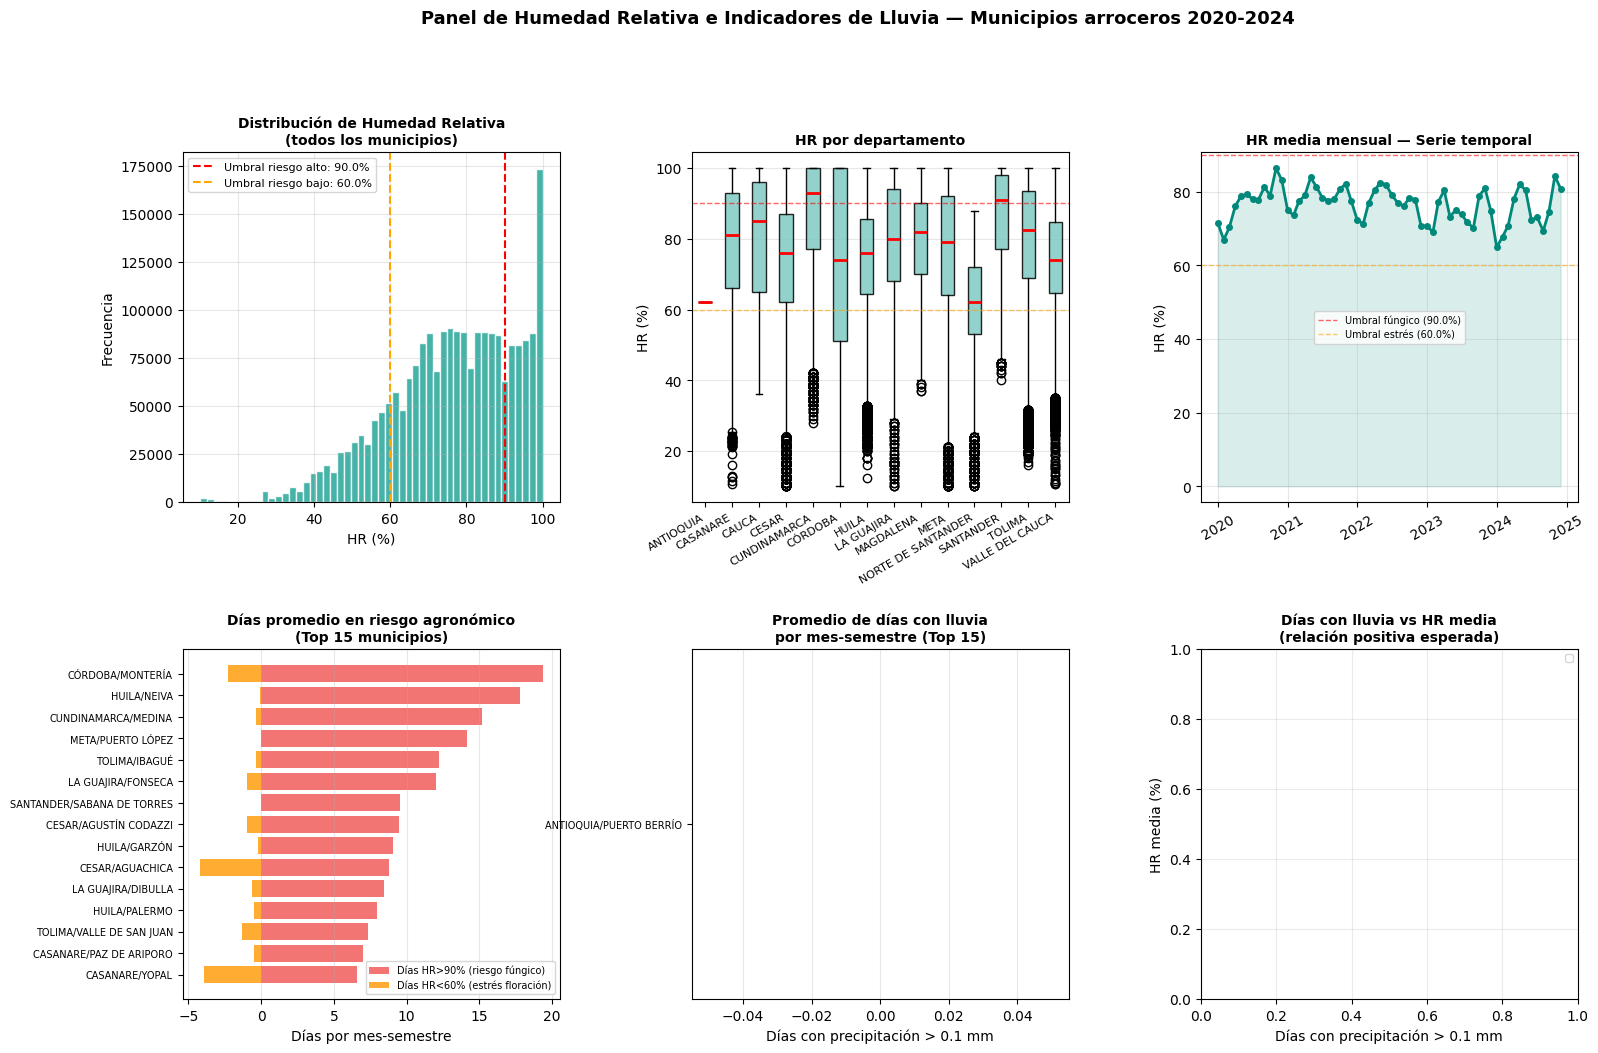

In [19]:
# ============================================================
# VISUALIZACIÓN — Humedad Relativa e Indicadores Agronómicos
# ============================================================

fig = plt.figure(figsize=(18, 11))
gs  = gridspec.GridSpec(2, 3, figure=fig, hspace=0.42, wspace=0.35)

# ── Gráfica 1: Histograma de HR ──────────────────────────────
ax1 = fig.add_subplot(gs[0, 0])
val = df_humedad['valorobservado'].dropna()
ax1.hist(val, bins=50, color='#26A69A', alpha=0.85, edgecolor='white')
ax1.axvline(HR_UMBRAL_ALTO, color='red',    linestyle='--', linewidth=1.5,
            label=f'Umbral riesgo alto: {HR_UMBRAL_ALTO}%')
ax1.axvline(HR_UMBRAL_BAJO, color='orange', linestyle='--', linewidth=1.5,
            label=f'Umbral riesgo bajo: {HR_UMBRAL_BAJO}%')
ax1.set_title('Distribución de Humedad Relativa\n(todos los municipios)',
              fontsize=10, fontweight='bold')
ax1.set_xlabel('HR (%)')
ax1.set_ylabel('Frecuencia')
ax1.legend(fontsize=8)
ax1.grid(True, alpha=0.3)

# ── Gráfica 2: Boxplot HR por departamento ───────────────────
ax2 = fig.add_subplot(gs[0, 1])
deptos    = df_humedad['departamento'].unique()
datos_box = [df_humedad[df_humedad['departamento']==d]['valorobservado'].dropna().values
             for d in deptos]
bp = ax2.boxplot(datos_box, labels=deptos, patch_artist=True,
                 medianprops={'color': 'red', 'linewidth': 2})
for patch in bp['boxes']:
    patch.set_facecolor('#80CBC4')
    patch.set_alpha(0.85)
ax2.axhline(HR_UMBRAL_ALTO, color='red',    linestyle='--', linewidth=1, alpha=0.6)
ax2.axhline(HR_UMBRAL_BAJO, color='orange', linestyle='--', linewidth=1, alpha=0.6)
ax2.set_title('HR por departamento',
              fontsize=10, fontweight='bold')
ax2.set_ylabel('HR (%)')
ax2.set_xticklabels(deptos, rotation=30, ha='right', fontsize=8)
ax2.grid(True, alpha=0.3, axis='y')

# ── Gráfica 3: Serie temporal mensual de HR ──────────────────
ax3 = fig.add_subplot(gs[0, 2])
df_serie_hr = (
    df_humedad_agr_sd
    .groupby(['Periodo','mes_periodo'])['hr_media']
    .mean().reset_index()
)
# Reconstruir fecha real
df_serie_hr['_anio']    = df_serie_hr['Periodo'].str[:4].astype(int)
df_serie_hr['_sem']     = df_serie_hr['Periodo'].str[4]
df_serie_hr['_offset']  = df_serie_hr['_sem'].map({'A': 0, 'B': 6})
df_serie_hr['_mes']     = df_serie_hr['mes_periodo'].astype(int) + df_serie_hr['_offset']
df_serie_hr['fecha']    = pd.to_datetime(
    df_serie_hr['_anio'].astype(str) + '-' +
    df_serie_hr['_mes'].astype(str).str.zfill(2) + '-01',
    format='%Y-%m-%d'
)
df_serie_hr = df_serie_hr.sort_values('fecha')
ax3.plot(df_serie_hr['fecha'], df_serie_hr['hr_media'],
         color='#00897B', linewidth=2, marker='o', markersize=4)
ax3.fill_between(df_serie_hr['fecha'], df_serie_hr['hr_media'],
                 alpha=0.15, color='#00897B')
ax3.axhline(HR_UMBRAL_ALTO, color='red',    linestyle='--', linewidth=1, alpha=0.6,
            label=f'Umbral fúngico ({HR_UMBRAL_ALTO}%)')
ax3.axhline(HR_UMBRAL_BAJO, color='orange', linestyle='--', linewidth=1, alpha=0.6,
            label=f'Umbral estrés ({HR_UMBRAL_BAJO}%)')
ax3.set_title('HR media mensual — Serie temporal',
              fontsize=10, fontweight='bold')
ax3.set_ylabel('HR (%)')
ax3.tick_params(axis='x', rotation=30)
ax3.legend(fontsize=7)
ax3.grid(True, alpha=0.3)

# ── Gráfica 4: Días de riesgo por municipio-periodo ──────────
ax4 = fig.add_subplot(gs[1, 0])
df_riesgo_mun = (
    df_humedad_agr_sd
    .groupby(['departamento','municipio'])[['hr_dias_riesgo_alto','hr_dias_riesgo_bajo']]
    .mean().reset_index()
    .sort_values('hr_dias_riesgo_alto', ascending=True)
    .tail(15)
)
y_pos = range(len(df_riesgo_mun))
ax4.barh(y_pos, df_riesgo_mun['hr_dias_riesgo_alto'],
         color='#EF5350', alpha=0.8, label='Días HR>90% (riesgo fúngico)')
ax4.barh(y_pos, -df_riesgo_mun['hr_dias_riesgo_bajo'],
         color='#FF9800', alpha=0.8, label='Días HR<60% (estrés floración)')
labels = (df_riesgo_mun['departamento'] + '/' + df_riesgo_mun['municipio']).tolist()
ax4.set_yticks(list(y_pos))
ax4.set_yticklabels(labels, fontsize=7)
ax4.set_title('Días promedio en riesgo agronómico\n(Top 15 municipios)',
              fontsize=10, fontweight='bold')
ax4.set_xlabel('Días por mes-semestre')
ax4.legend(fontsize=7)
ax4.grid(True, alpha=0.3, axis='x')

# ── Gráfica 5: Días con lluvia por municipio ─────────────────
ax5 = fig.add_subplot(gs[1, 1])
df_lluvia_mun = (
    df_ind_lluvia
    .groupby(['departamento','municipio'])['prec_dias_lluvia']
    .mean().reset_index()
    .sort_values('prec_dias_lluvia', ascending=True)
    .tail(15)
)
ax5.barh(
    (df_lluvia_mun['departamento'] + '/' + df_lluvia_mun['municipio']),
    df_lluvia_mun['prec_dias_lluvia'],
    color='#1565C0', alpha=0.8
)
ax5.set_title('Promedio de días con lluvia\npor mes-semestre (Top 15)',
              fontsize=10, fontweight='bold')
ax5.set_xlabel('Días con precipitación > 0.1 mm')
ax5.tick_params(axis='y', labelsize=7)
ax5.grid(True, alpha=0.3, axis='x')

# ── Gráfica 6: HR vs Días con lluvia (scatter) ───────────────
ax6 = fig.add_subplot(gs[1, 2])
df_scatter = df_humedad_agr_sd.merge(
    df_ind_lluvia[['Periodo','departamento','municipio','mes_periodo','prec_dias_lluvia']],
    on=['Periodo','departamento','municipio','mes_periodo'],
    how='inner'
)
deptos_unicos = df_scatter['departamento'].unique()
colores_dep   = plt.cm.tab10(np.linspace(0, 1, len(deptos_unicos)))
for dep, color in zip(deptos_unicos, colores_dep):
    sub = df_scatter[df_scatter['departamento'] == dep]
    ax6.scatter(sub['prec_dias_lluvia'], sub['hr_media'],
                s=30, alpha=0.6, color=color, label=dep,
                edgecolors='white', linewidths=0.3)
# Línea de tendencia
x_v = df_scatter['prec_dias_lluvia'].dropna()
y_v = df_scatter['hr_media'].dropna()
if len(x_v) > 5:
    idx = x_v.index.intersection(y_v.index)
    z = np.polyfit(x_v[idx], y_v[idx], 1)
    p = np.poly1d(z)
    xr = np.linspace(x_v.min(), x_v.max(), 100)
    ax6.plot(xr, p(xr), 'k--', linewidth=1.5, alpha=0.7,
             label=f'Tendencia (pend={z[0]:.2f})')
ax6.set_title('Días con lluvia vs HR media\n(relación positiva esperada)',
              fontsize=10, fontweight='bold')
ax6.set_xlabel('Días con precipitación > 0.1 mm')
ax6.set_ylabel('HR media (%)')
ax6.legend(fontsize=7, ncol=2)
ax6.grid(True, alpha=0.25)

plt.suptitle(
    'Panel de Humedad Relativa e Indicadores de Lluvia — Municipios arroceros 2020-2024',
    fontsize=13, fontweight='bold', y=1.01
)
plt.show()

---
## ✅ CELDA 18 — Resumen de ejecución del módulo

In [20]:
# ============================================================
# RESUMEN FINAL — MOD-05 completado
# ============================================================

print('=' * 65)
print('  ✅ MOD-05 — Humedad Relativa + Indicadores de Lluvia  COMPLETADO')
print('=' * 65)

print('\n💧 Humedad Relativa (IDEAM):')
salidas_hr = [
    ('data/raw/',       '05_raw_Humedad_IDEAM.parquet',
     f'Descarga original — {df_humedad_raw.shape[0]:,} registros'),
    ('data/processed/', '25_DF_Humedad_Long.xlsx',
     f'Serie larga con calendario — {df_humedad.shape[0]:,} filas'),
    ('data/processed/', '26_DF_Humedad_Agr.xlsx',
     f'Métricas diarias — {df_humedad_agr.shape[0]:,} filas'),
    ('data/processed/', '27_DF_Humedad_Agr_SD.xlsx',
     f'Métricas mes semestral — {df_humedad_agr_sd.shape[0]:,} filas'),
    ('data/processed/', '28_DF_Humedad_Wide.xlsx',
     f'Formato wide m1..m6 — {df_humedad_wide.shape[0]:,} filas × {df_humedad_wide.shape[1]} cols'),
]
for carpeta, archivo, desc in salidas_hr:
    print(f'   📄 {carpeta}{archivo}')
    print(f'      {desc}')

print('\n🌧️  Indicadores de Precipitación (calculados desde MOD-04):')
salidas_lluvia = [
    ('data/processed/', '29_DF_Indicadores_Lluvia.xlsx',
     f'Días con lluvia + prec. mínima — {df_ind_lluvia.shape[0]:,} filas (largo) + {df_ind_lluvia_wide.shape[0]:,} (wide)'),
]
for carpeta, archivo, desc in salidas_lluvia:
    print(f'   📄 {carpeta}{archivo}')
    print(f'      {desc}')

print('\n📊 DataFrames disponibles para módulos siguientes:')
print('   df_humedad           → serie larga con banderas de riesgo')
print('   df_humedad_agr       → métricas diarias')
print('   df_humedad_agr_sd    → métricas por mes semestral')
print('   df_humedad_wide      → LISTO para MOD-06 ✅')
print('   df_ind_lluvia        → indicadores largo')
print('   df_ind_lluvia_wide   → LISTO para MOD-06 ✅')

print('\n🗺️  Cobertura:')
print(f'   Periodos cubiertos: {sorted(df_humedad_wide["Periodo"].unique())}')
print(f'   Municipios con datos HR: {df_humedad_wide[["departamento","municipio"]].drop_duplicates().shape[0]}')

print('\n➡️  Siguiente módulo : MOD-06 — Consolidación del Dataset Maestro')
print('    Entradas esperadas:')
print('      11_DF_Produccion_Agricola.xlsx  (MOD-01)')
print('      18_DF_Temperatura_Wide.xlsx     (MOD-03)')
print('      22_DF_Precipitacion_Wide.xlsx   (MOD-04)')
print('      24_DF_Radiacion_Wide.xlsx       (MOD-04)')
print('      28_DF_Humedad_Wide.xlsx         (MOD-05 — este módulo)')
print('      29_DF_Indicadores_Lluvia.xlsx   (MOD-05 — este módulo)')
print('=' * 65)

  ✅ MOD-05 — Humedad Relativa + Indicadores de Lluvia  COMPLETADO

💧 Humedad Relativa (IDEAM):
   📄 data/raw/05_raw_Humedad_IDEAM.parquet
      Descarga original — 2,291,135 registros
   📄 data/processed/25_DF_Humedad_Long.xlsx
      Serie larga con calendario — 2,238,794 filas
   📄 data/processed/26_DF_Humedad_Agr.xlsx
      Métricas diarias — 27,154 filas
   📄 data/processed/27_DF_Humedad_Agr_SD.xlsx
      Métricas mes semestral — 1,148 filas
   📄 data/processed/28_DF_Humedad_Wide.xlsx
      Formato wide m1..m6 — 253 filas × 45 cols

🌧️  Indicadores de Precipitación (calculados desde MOD-04):
   📄 data/processed/29_DF_Indicadores_Lluvia.xlsx
      Días con lluvia + prec. mínima — 13 filas (largo) + 3 (wide)

📊 DataFrames disponibles para módulos siguientes:
   df_humedad           → serie larga con banderas de riesgo
   df_humedad_agr       → métricas diarias
   df_humedad_agr_sd    → métricas por mes semestral
   df_humedad_wide      → LISTO para MOD-06 ✅
   df_ind_lluvia        → i